In [3]:
import pyodbc

# Nom de votre serveur
server = r"DESKTOP-RRT65BQ\SQLEXPRESS"
database = (
    "TIA"  # Remplacez par le nom de votre base de données
)

try:
  # Connexion avec l'authentification Windows
  conn = pyodbc.connect(
      f"DRIVER={{ODBC Driver 17 for SQL Server}};"
      f"SERVER={server};"
      f"DATABASE={database};"
      f"Trusted_Connection=yes;"
  )
  print("Super ! Connexion à la base de données réussie !")

  # Fermer la connexion
  conn.close()

except Exception as e:
  # Capturer et afficher les informations d'erreur
  print(f"Échec de la connexion. Raison de l'erreur : {e}")

Super ! Connexion à la base de données réussie !


In [8]:

import pyodbc
import pandas as pd

# =====================================
# 1. Connect to AdventureWorks2025
# =====================================

server = r"DESKTOP-RRT65BQ\SQLEXPRESS"
database = "AdventureWorks2025"

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

print("Successfully connected to:", database)

# =====================================
# 2. Extract all tables
# =====================================

cursor = conn.cursor()

cursor.execute("""
SELECT
    s.name AS SchemaName,
    t.name AS TableName,
    SUM(p.rows) AS TotalRows
FROM sys.tables AS t
INNER JOIN sys.schemas AS s
    ON t.schema_id = s.schema_id
INNER JOIN sys.partitions AS p
    ON t.object_id = p.object_id
WHERE p.index_id IN (0, 1)
GROUP BY
    s.name,
    t.name
ORDER BY
    s.name,
    t.name;
""")

tables = pd.DataFrame.from_records(
    cursor.fetchall(),
    columns=[col[0] for col in cursor.description]
)

print("\n========== ALL TABLES ==========")
print(tables.to_string(index=False))

print("\nTotal number of tables:", len(tables))

# =====================================
# 3. Extract all columns
# =====================================

cursor.execute("""
SELECT
    s.name AS SchemaName,
    t.name AS TableName,
    c.name AS ColumnName,
    ty.name AS DataType,
    c.max_length AS MaxLength,
    c.is_nullable AS IsNullable
FROM sys.tables AS t
INNER JOIN sys.schemas AS s
    ON t.schema_id = s.schema_id
INNER JOIN sys.columns AS c
    ON t.object_id = c.object_id
INNER JOIN sys.types AS ty
    ON c.user_type_id = ty.user_type_id
ORDER BY
    s.name,
    t.name,
    c.column_id;
""")

columns = pd.DataFrame.from_records(
    cursor.fetchall(),
    columns=[col[0] for col in cursor.description]
)

print("\n========== ALL COLUMNS ==========")
print(columns.to_string(index=False))

# =====================================
# 4. Save metadata
# =====================================

tables.to_csv(
    "database_tables.csv",
    index=False,
    encoding="utf-8-sig"
)

columns.to_csv(
    "database_columns.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nMetadata extraction completed!")



Successfully connected to: AdventureWorks2025

========== ALL TABLES ==========
    SchemaName                             TableName  TotalRows
           dbo                        AWBuildVersion          1
           dbo                           DatabaseLog        927
           dbo                              ErrorLog          0
HumanResources                            Department         16
HumanResources                              Employee        290
HumanResources             EmployeeDepartmentHistory        296
HumanResources                    EmployeePayHistory        316
HumanResources                          JobCandidate         13
HumanResources                                 Shift          3
        Person                               Address      19614
        Person                           AddressType          6
        Person                        BusinessEntity      20777
        Person                 BusinessEntityAddress      19614
        Person          

In [9]:
import pyodbc
import pandas as pd

# 1. Connect to AdventureWorks2025
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=DESKTOP-RRT65BQ\\SQLEXPRESS;"
    "DATABASE=AdventureWorks2025;"
    "Trusted_Connection=yes;"
)

# 2. Check order status distribution
query_status = """
SELECT
    Status,
    COUNT(*) AS NumberOfOrders
FROM Sales.SalesOrderHeader
GROUP BY Status
ORDER BY Status;
"""

cursor = conn.cursor()
cursor.execute(query_status)

status_data = cursor.fetchall()

df_status = pd.DataFrame.from_records(
    status_data,
    columns=["Status", "NumberOfOrders"]
)

print("Order Status Distribution:")
display(df_status)

Order Status Distribution:


,Status,NumberOfOrders
0,5,31465


In [10]:
# Extract Customer table
query_customer = """
SELECT *
FROM Sales.Customer;
"""

cursor.execute(query_customer)

customer_data = cursor.fetchall()

df_customer = pd.DataFrame.from_records(
    customer_data,
    columns=[column[0] for column in cursor.description]
)

# Extract SalesOrderHeader table
query_orders = """
SELECT *
FROM Sales.SalesOrderHeader;
"""

cursor.execute(query_orders)

order_data = cursor.fetchall()

df_orders = pd.DataFrame.from_records(
    order_data,
    columns=[column[0] for column in cursor.description]
)

# Basic information
print("Customer dataset:", df_customer.shape)
print("Order dataset:", df_orders.shape)

# Missing values
print("\nCustomer missing values:")
display(df_customer.isnull().sum())

print("\nOrder missing values:")
display(df_orders.isnull().sum())

# Duplicate records
print("\nCustomer duplicate rows:", df_customer.duplicated().sum())
print("Order duplicate rows:", df_orders.duplicated().sum())

Customer dataset: (19820, 7)
Order dataset: (31465, 26)

Customer missing values:


CustomerID           0
PersonID           701
StoreID          18484
TerritoryID          0
AccountNumber        0
rowguid              0
ModifiedDate         0
dtype: int64


Order missing values:


SalesOrderID                  0
RevisionNumber                0
OrderDate                     0
DueDate                       0
ShipDate                      0
Status                        0
OnlineOrderFlag               0
SalesOrderNumber              0
PurchaseOrderNumber       27659
AccountNumber                 0
CustomerID                    0
SalesPersonID             27659
TerritoryID                   0
BillToAddressID               0
ShipToAddressID               0
ShipMethodID                  0
CreditCardID               1131
CreditCardApprovalCode     1131
CurrencyRateID            17489
SubTotal                      0
TaxAmt                        0
Freight                       0
TotalDue                      0
Comment                   31465
rowguid                       0
ModifiedDate                  0
dtype: int64


Customer duplicate rows: 0
Order duplicate rows: 0


In [11]:
# 1. Convert OrderDate to datetime
df_orders["OrderDate"] = pd.to_datetime(df_orders["OrderDate"])

# 2. Define the reference date
reference_date = df_orders["OrderDate"].max() + pd.Timedelta(days=1)

# 3. Calculate RFM features
df_rfm = df_orders.groupby("CustomerID").agg(
    Recency=("OrderDate", lambda x: (reference_date - x.max()).days),
    Frequency=("SalesOrderID", "count"),
    Monetary=("TotalDue", "sum"),
    AverageOrderValue=("TotalDue", "mean")
).reset_index()

# 4. Add customer territory information
df_rfm = df_rfm.merge(
    df_customer[["CustomerID", "TerritoryID"]],
    on="CustomerID",
    how="left"
)

# 5. Inspect the new dataset
print("RFM dataset shape:", df_rfm.shape)

print("\nFirst 5 rows:")
display(df_rfm.head())

print("\nMissing values:")
display(df_rfm.isnull().sum())

print("\nDescriptive statistics:")
display(df_rfm.describe())

RFM dataset shape: (19119, 6)

First 5 rows:


,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,TerritoryID
0,11000,271,3,9115.1341,3038.378033,9
1,11001,50,3,7054.1875,2351.395833,9
2,11002,340,3,8966.0143,2988.671433,9
3,11003,264,3,8993.9155,2997.971833,9
4,11004,273,3,9056.5911,3018.8637,9



Missing values:


CustomerID           0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
TerritoryID          0
dtype: int64


Descriptive statistics:


,CustomerID,Recency,Frequency,TerritoryID
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,20559.000000,191.267483,1.645745,5.861447
std,5519.324234,150.423605,1.457054,3.052612
min,11000.000000,1.000000,1.000000,1.000000
25%,15779.500000,86.000000,1.000000,4.000000
50%,20559.000000,166.000000,1.000000,6.000000
75%,25338.500000,264.000000,2.000000,9.000000
max,30118.000000,1127.000000,28.000000,10.000000


In [12]:
# 1. Check data types
print("Data types:")
display(df_rfm.dtypes)

# 2. Check missing values
print("\nMissing values:")
display(df_rfm.isnull().sum())

# 3. Descriptive statistics
print("\nDescriptive statistics:")
display(df_rfm.describe())

# 4. Check unique customers
print("\nNumber of unique customers:")
print(df_rfm["CustomerID"].nunique())

# 5. Check negative and zero values
print("\nNon-positive values:")

for col in ["Recency", "Frequency", "Monetary", "AverageOrderValue"]:
    print(col, ":", (df_rfm[col] <= 0).sum())

Data types:


CustomerID            int64
Recency               int64
Frequency             int64
Monetary             object
AverageOrderValue    object
TerritoryID           int64
dtype: object


Missing values:


CustomerID           0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
TerritoryID          0
dtype: int64


Descriptive statistics:


,CustomerID,Recency,Frequency,TerritoryID
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,20559.000000,191.267483,1.645745,5.861447
std,5519.324234,150.423605,1.457054,3.052612
min,11000.000000,1.000000,1.000000,1.000000
25%,15779.500000,86.000000,1.000000,4.000000
50%,20559.000000,166.000000,1.000000,6.000000
75%,25338.500000,264.000000,2.000000,9.000000
max,30118.000000,1127.000000,28.000000,10.000000



Number of unique customers:
19119

Non-positive values:
Recency : 0
Frequency : 0
Monetary : 0
AverageOrderValue : 0


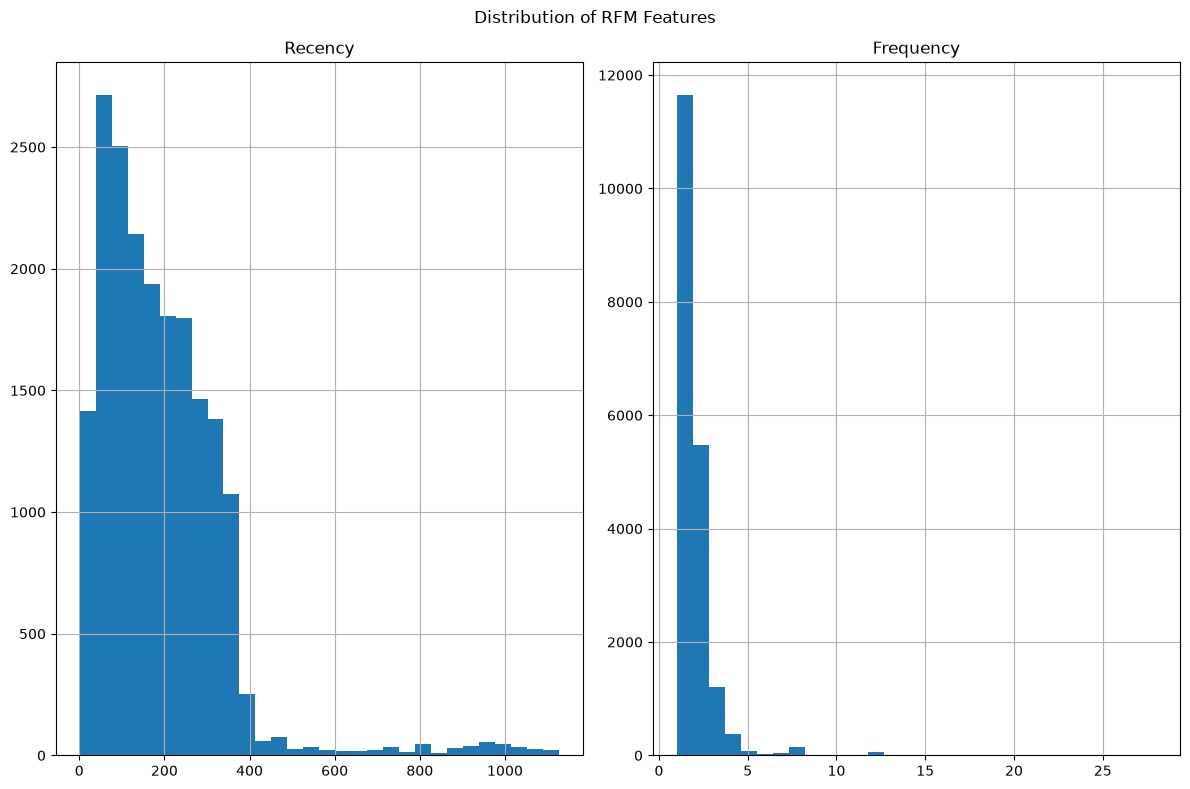

In [13]:
import matplotlib.pyplot as plt

features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue"
]

df_rfm[features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of RFM Features")
plt.tight_layout()
plt.show()

In [14]:
# Convert monetary variables to numeric types
df_rfm["Monetary"] = pd.to_numeric(df_rfm["Monetary"])

df_rfm["AverageOrderValue"] = pd.to_numeric(
    df_rfm["AverageOrderValue"]
)

# Select numerical clustering features
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue"
]

df_cluster = df_rfm[features].copy()

# Check data types
print("Data types:")
display(df_cluster.dtypes)

# Check descriptive statistics
print("\nDescriptive statistics:")
display(df_cluster.describe())

Data types:


Recency                int64
Frequency              int64
Monetary             float64
AverageOrderValue    float64
dtype: object


Descriptive statistics:


,Recency,Frequency,Monetary,AverageOrderValue
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,191.267483,1.645745,6444.729647,1678.117828
std,150.423605,1.457054,43756.276004,6034.784983
min,1.000000,1.000000,1.518300,1.518300
25%,86.000000,1.000000,60.752900,45.829900
50%,166.000000,1.000000,606.622900,606.622900
75%,264.000000,2.000000,3119.149400,2152.834250
max,1127.000000,28.000000,989184.082000,151704.902175


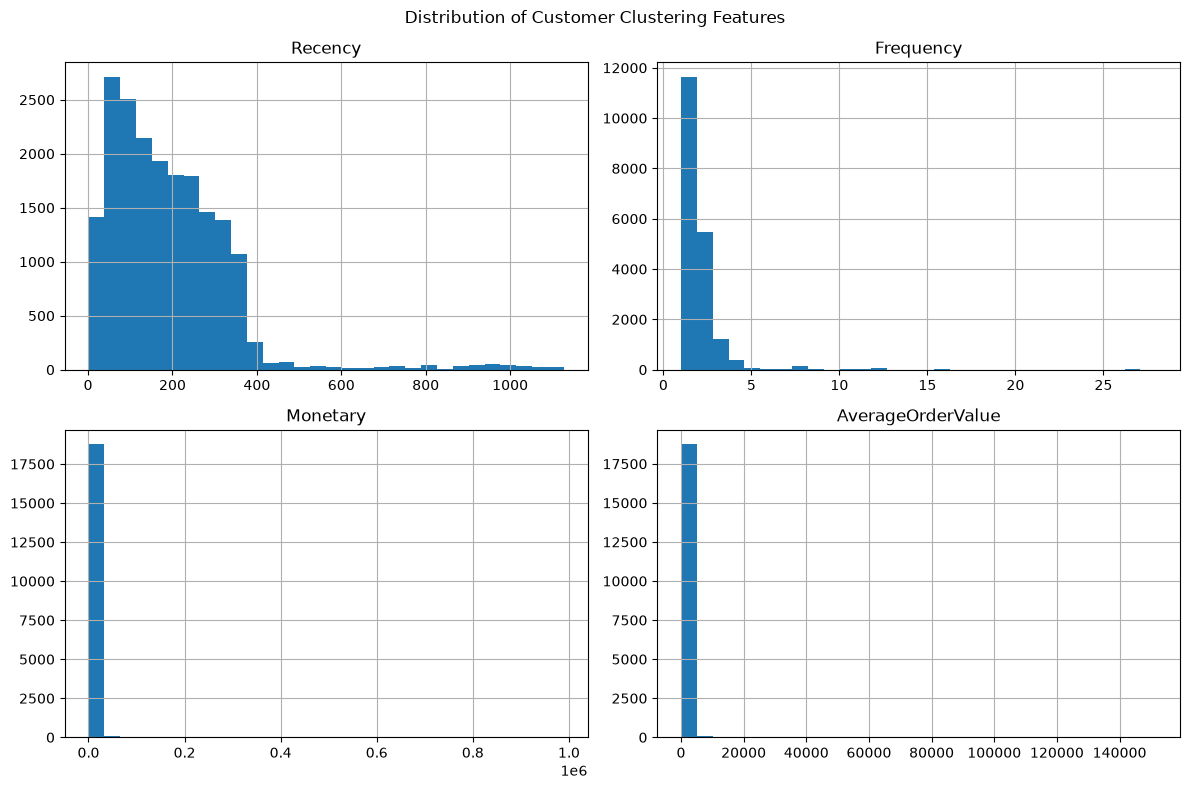

In [15]:
import matplotlib.pyplot as plt

df_cluster.hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of Customer Clustering Features")
plt.tight_layout()
plt.show()

In [16]:
print("Skewness:")
display(df_cluster.skew())

Skewness:


Recency               2.435350
Frequency             7.388770
Monetary             12.797698
AverageOrderValue    10.846958
dtype: float64

In [17]:
for col in features:

    Q1 = df_cluster[col].quantile(0.25)
    Q3 = df_cluster[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_cluster[
        (df_cluster[col] < lower_bound) |
        (df_cluster[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of outliers:", len(outliers))


Recency
Lower bound: -181.0
Upper bound: 531.0
Number of outliers: 465

Frequency
Lower bound: -0.5
Upper bound: 3.5
Number of outliers: 793

Monetary
Lower bound: -4526.84185
Upper bound: 7706.74415
Number of outliers: 839

AverageOrderValue
Lower bound: -3114.6766249999996
Upper bound: 5313.340775
Number of outliers: 364


Skewness after Log Transformation:


Recency             -1.063682
Frequency            2.197602
Monetary             0.140627
AverageOrderValue   -0.046275
dtype: float64

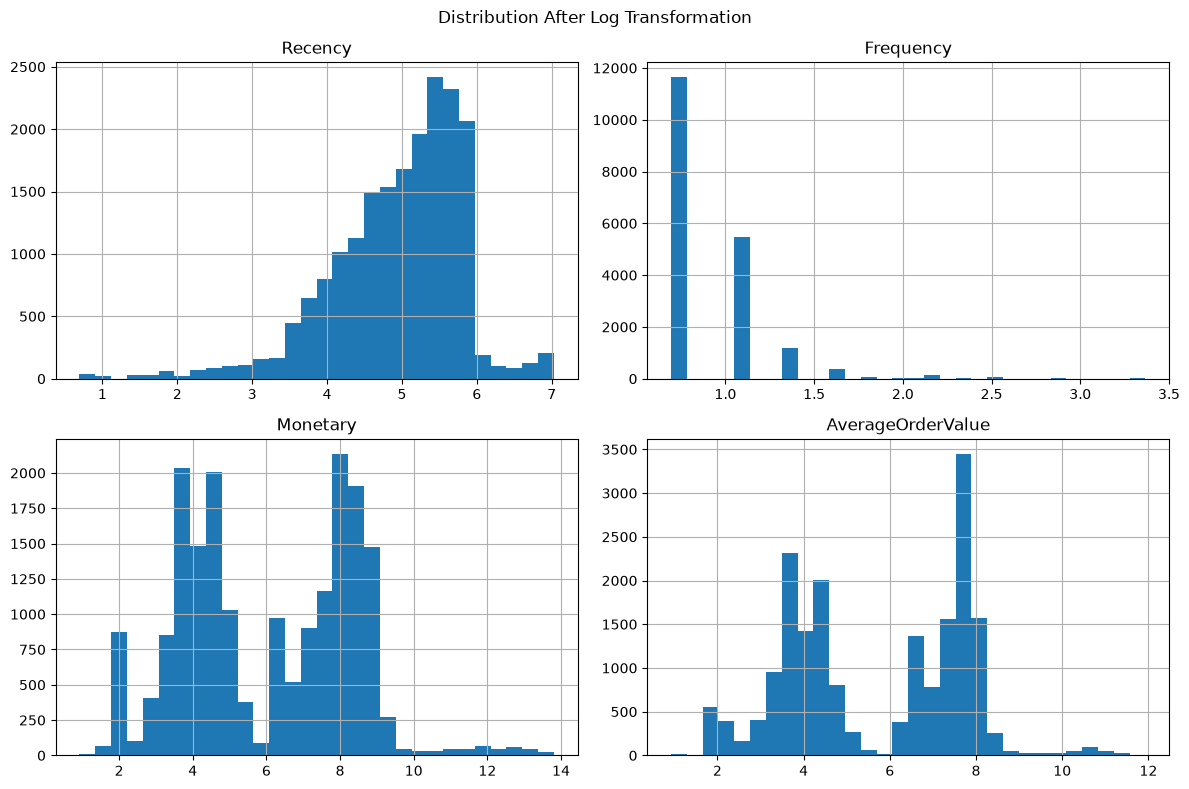

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Apply Log Transformation
df_cluster_log = np.log1p(df_cluster)

# Check skewness after transformation
print("Skewness after Log Transformation:")
display(df_cluster_log.skew())

# Visualize distributions after transformation
df_cluster_log.hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution After Log Transformation")
plt.tight_layout()
plt.show()

In [19]:
skewness_comparison = pd.DataFrame({
    "Before Log": df_cluster.skew(),
    "After Log": df_cluster_log.skew()
})

display(skewness_comparison)

,Before Log,After Log
Recency,2.435350,-1.063682
Frequency,7.388770,2.197602
Monetary,12.797698,0.140627
AverageOrderValue,10.846958,-0.046275


In [20]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the transformed features
df_cluster_scaled = pd.DataFrame(
    scaler.fit_transform(df_cluster_log),
    columns=df_cluster_log.columns,
    index=df_cluster_log.index
)

# Check standardized data
print("Standardized data:")
display(df_cluster_scaled.head())

print("\nMean:")
display(df_cluster_scaled.mean())

print("\nStandard deviation:")
display(df_cluster_scaled.std())

Standardized data:


,Recency,Frequency,Monetary,AverageOrderValue
0,0.744496,1.49733,1.331341,1.128007
1,-1.164131,1.49733,1.220409,1.003269
2,1.002268,1.49733,1.324202,1.119979
3,0.714769,1.49733,1.325547,1.121491
4,0.752849,1.49733,1.328552,1.124871



Mean:


Recency             -3.805616e-16
Frequency           -2.616361e-16
Monetary             2.586630e-16
AverageOrderValue   -2.423107e-16
dtype: float64


Standard deviation:


Recency              1.000026
Frequency            1.000026
Monetary             1.000026
AverageOrderValue    1.000026
dtype: float64